# 3장 1강 · 객체 탐지 및 세그멘테이션 평가

**실습문제**

사진 한 장에서 개의 종류를 맞히고도 머리 박스는 틀릴 수 있습니다. 또 머리 위치가 어긋난 사진에서도 몸 전체의 윤곽은 잘 나올 수 있습니다. 이 실습에서는 같은 Oxford 사진을 세 가지 질문으로 평가합니다.

| 구분 | 제출할 결과 |
|---|---|
| 필수 1 | 전처리와 학습 기록, 머리 박스의 면적 검산, IoU 기준에 따른 판정 |
| 필수 2 | 중복·클래스 오류 판정표, 실제 예측의 Precision·Recall, 클래스별 AP와 mAP |
| 독립 과제 | 4×4 예제의 위치 수정, 실제 몸 마스크의 픽셀 오차 그림, 사진별 평균과 검사 범위에 대한 결론 |

**데이터와 실행 준비**　기존 `oxford_dataset(1).zip` 또는 `oxford_dataset.zip`을 노트북 옆에 둡니다. 이 수업용 ZIP에는 사진과 머리 좌표가 있고, 몸 마스크 파일은 없습니다. 첫 실행 시 Oxford 공식 픽셀 주석 `annotations.tar.gz`(약 19 MB)와 ImageNet 사전학습 ResNet18 가중치(약 45 MB)를 내려받습니다. 이미 받은 주석은 노트북 옆에 두면 됩니다. 주석의 값 1은 동물, 2는 배경, 3은 미분류 영역이며 3은 학습 손실과 평가에서 모두 제외합니다. [Oxford-IIIT Pet 공식 주석](https://www.robots.ox.ac.uk/~vgg/data/pets/data/annotations.tar.gz)

**실행 환경**　Python 3.10 이상, PyTorch·torchvision, NumPy, pandas, Pillow와 Jupyter가 필요합니다. 제작 환경은 CPU, torch 2.6.0, torchvision 0.21.0입니다. 시드 42를 고정했고, 환경에 따라 소수점 아래 수치가 조금 다를 수 있습니다.

**실험 조건**　사진마다 주석된 머리가 하나인 경우만 사용합니다. 제공본에서 JPEG·머리 주석을 함께 쓸 수 있는 사진 중 고양이·개 각각 학습 96장, 평가 24장을 선택합니다. 출력은 사진당 종 한 개, 머리 박스 한 개, 몸 전체의 전경 마스크 한 장입니다. 점수는 두 종 중 선택한 종의 확률이므로 박스가 정확할 확률까지 나타내지는 않습니다. 여러 객체가 있는 장면의 정식 COCO 성능과는 평가 조건이 다릅니다.

**실행 순서**　공통 준비 셀을 위에서 아래로 실행하면 두 파일 모두 실제로 모델을 학습해 같은 예측 표를 만듭니다. 이후 필수 1·필수 2·독립 과제 중 원하는 절부터 시작할 수 있습니다. 연습용 고정 후보와 4×4 배열은 손계산용이며, 모델 성능 표는 평가 사진 48장의 실제 출력으로 계산합니다.

### 공통 준비 1 · 파일 확인과 사진 분할

In [2]:
from pathlib import Path
from io import BytesIO
import tarfile
import hashlib
from urllib.request import urlretrieve
from zipfile import ZipFile
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw
from IPython.display import display
import torch
from torch import nn
from torch.nn import functional as F
from torchvision.models import resnet18, ResNet18_Weights
from torchvision.transforms import functional as T

torch.set_num_threads(2)
SEED, SIZE, MASK_SIZE = 42, 160, 40
species = ["cat", "dog"]
coords = ["xmin","ymin","xmax","ymax"]
data_path = next((p for p in [Path("C:/Users/jihun/OneDrive/Desktop/DS 실습자료/LV2/이미지 분석/DATA/1장, 2장(1,2),3장(1),4장/Oxford/oxford_dataset/oxford_dataset.zip")] if p.is_file()), None)
if data_path is None:
    raise FileNotFoundError("노트북 옆에 수업용 oxford_dataset.zip 또는 oxford_dataset(1).zip을 두세요.")
trimap_file = Path("annotations.tar.gz")
if not trimap_file.is_file():
    temp_file = trimap_file.with_suffix(".download")
    urlretrieve("https://www.robots.ox.ac.uk/~vgg/data/pets/data/annotations.tar.gz", temp_file)
    if hashlib.sha256(temp_file.read_bytes()).hexdigest() != "52425fb6de5c424942b7626b428656fcbd798db970a937df61750c0f1d358e91":
        raise ValueError("다운로드한 Oxford 주석 파일의 내용이 다릅니다.")
    temp_file.replace(trimap_file)

with ZipFile(data_path) as z:
    boxes = pd.read_csv(z.open("head_boxes.csv"))
    present = set(z.namelist())
pool = boxes.loc[boxes.image_path.isin(present) & boxes.object_name.isin(species)].copy()
pool = pool[~pool.image_id.duplicated(keep=False)].set_index("image_id").sort_index()
# 예제로 읽는 사진 3장은 학습 후보에서 먼저 제외합니다.
demo_ids = ["Abyssinian_1","beagle_110","beagle_111"]
train_ids, eval_ids = [], []
for name in species:
    fixed = [i for i in demo_ids if pool.loc[i,"object_name"] == name]
    candidates = pool.loc[pool.object_name == name].drop(index=fixed)
    order = candidates.sample(frac=1,random_state=SEED).index.tolist()
    train_ids.extend(order[:96])
    eval_ids.extend(fixed + order[96:96+24-len(fixed)])
assert len(set(train_ids)) == 192 and len(set(eval_ids)) == 48
assert set(train_ids).isdisjoint(eval_ids)
print("가용 단일 머리 주석 사진",len(pool)," / 학습",len(train_ids),"/ 평가",len(eval_ids))

FileNotFoundError: 노트북 옆에 수업용 oxford_dataset.zip 또는 oxford_dataset(1).zip을 두세요.

### 공통 준비 2 · 원본 사진, 머리 박스, 몸 마스크의 크기 맞추기

In [ ]:
all_ids = train_ids + eval_ids
wanted = {f"annotations/trimaps/{key}.png": key for key in all_ids}
trimaps = {}
with tarfile.open(trimap_file, "r|gz") as tar:
    for entry in tar:
        if entry.name in wanted and entry.isfile():
            with Image.open(BytesIO(tar.extractfile(entry).read())) as im:
                trimaps[wanted[entry.name]] = np.array(im)
assert len(trimaps) == len(all_ids)

def load_photo(key):
    with ZipFile(data_path) as z, Image.open(BytesIO(z.read(pool.loc[key,"image_path"]))) as im:
        return im.convert("RGB")

def prepare_sample(im, key):
    row = pool.loc[key]
    w,h = im.size
    rgb = im.resize((SIZE,SIZE), Image.Resampling.BILINEAR)
    x = T.normalize(T.to_tensor(rgb), [0.485,0.456,0.406], [0.229,0.224,0.225])
    norm_box = row[coords].to_numpy(dtype=np.float32) / np.array([w,h,w,h], dtype=np.float32)
    orig = trimaps[key]
    assert orig.shape == (h,w)
    mask = np.array(Image.fromarray(orig).resize((MASK_SIZE,MASK_SIZE), Image.Resampling.NEAREST))
    return x, species.index(row.object_name), norm_box, mask

def extract_inputs():
    weights = ResNet18_Weights.DEFAULT
    base = resnet18(weights=weights).eval()
    backbone = nn.Sequential(*list(base.children())[:7]).eval()
    feats, labels, targets, masks = [], [], [], []
    with torch.no_grad(), ZipFile(data_path) as z:
        for start in range(0, len(all_ids), 12):
            rgb_batch = []
            for key in all_ids[start:start+12]:
                with Image.open(BytesIO(z.read(pool.loc[key,"image_path"]))) as im:
                    x,y,b,m = prepare_sample(im.convert("RGB"),key)
                rgb_batch.append(x)
                labels.append(y)
                targets.append(b)
                masks.append(m)
            feats.append(backbone(torch.stack(rgb_batch)))
    return torch.cat(feats), torch.tensor(labels), torch.from_numpy(np.stack(targets)), torch.from_numpy(np.stack(masks))

### 공통 준비 3 · 사진 한 장에서 종·머리 위치·몸 영역을 예측하는 모델

In [ ]:
class PetHeads(nn.Module):
    def __init__(self):
        super().__init__()
        self.kind = nn.Linear(256,2)
        self.region = nn.Sequential(nn.AdaptiveAvgPool2d(3), nn.Flatten(), nn.Linear(256*9,64),
                                    nn.ReLU(), nn.Linear(64,4))
        self.body = nn.Sequential(nn.Conv2d(256,32,3,padding=1), nn.ReLU(), nn.Conv2d(32,1,1))

    def forward(self, f):
        cls = self.kind(f.mean(dim=(2,3)))
        center, span = self.region(f).sigmoid().split(2,dim=1)
        xyxy = torch.cat([center-span/2, center+span/2], dim=1).clamp(0,1)
        mask = F.interpolate(self.body(f), size=(MASK_SIZE,MASK_SIZE), mode="bilinear",align_corners=False)
        return cls, xyxy, mask[:,0]

def fit_heads(features, labels, boxes, masks):
    torch.manual_seed(SEED)
    net = PetHeads()
    optimizer = torch.optim.Adam(net.parameters(), lr=0.001)
    n = len(train_ids)
    trace = []
    for epoch in range(8):
        totals = np.zeros(3)
        for idx in torch.randperm(n).split(16):
            cls, predicted_box, logits = net(features[idx])
            trimap = masks[idx]
            valid = trimap != 3
            kind_loss = F.cross_entropy(cls,labels[idx])
            box_loss = F.smooth_l1_loss(predicted_box,boxes[idx],beta=0.1)
            mask_loss = F.binary_cross_entropy_with_logits(logits[valid],(trimap[valid]==1).float())
            loss = kind_loss + 4*box_loss + mask_loss
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            totals += len(idx)*np.array([kind_loss.item(),box_loss.item(),mask_loss.item()])
        trace.append(totals/n)
    history = pd.DataFrame(trace, columns=["class_loss","box_loss","mask_loss"],index=range(1,9))
    history.index.name = "epoch"
    return net.eval(), history

### 공통 준비 4 · 학습하고 처음 보는 사진 48장의 예측 보관하기

In [ ]:
features, y, head_boxes, body_masks = extract_inputs()
net, history = fit_heads(features, y, head_boxes, body_masks)
display(history.round(4))
print("특징/라벨/머리 박스/몸 마스크",tuple(features.shape),tuple(y.shape),tuple(head_boxes.shape),tuple(body_masks.shape))

with torch.no_grad():
    scores, norm_boxes, mask_logits = net(features[len(train_ids):])
    top_score, top_label = scores.softmax(dim=1).max(dim=1)
    body_prob = mask_logits.sigmoid().numpy()
records = []
for i,key in enumerate(eval_ids):
    w,h = load_photo(key).size
    box = norm_boxes[i].numpy() * [w,h,w,h]
    records.append((key, species[top_label[i].item()],top_score[i].item(),tuple(box)))
predictions = pd.DataFrame(records,columns=["image","label","score","box"])
gt = pool.loc[eval_ids]
display(predictions.drop(columns="box").head())

,class_loss,box_loss,mask_loss
epoch,,,
1,0.6955,0.0785,0.4876
2,0.6860,0.0549,0.2445
3,0.6783,0.0413,0.1764
4,0.6712,0.0323,0.1514
5,0.6654,0.0259,0.1392
6,0.6592,0.0209,0.1309
7,0.6513,0.0177,0.1265
8,0.6448,0.0151,0.1227


특징/라벨/머리 박스/몸 마스크 (240, 256, 10, 10) (240,) (240, 4) (240, 40, 40)


,image,label,score
0,Abyssinian_1,cat,0.542233
1,Birman_116,cat,0.526019
2,Egyptian_Mau_12,cat,0.564239
3,Persian_156,cat,0.507792
4,British_Shorthair_102,cat,0.541080


### 공통 준비 5 · 문항에서 호출할 평가 함수와 손계산 자료

In [ ]:
def box_parts(a,b):
    left, top = max(a[0],b[0]), max(a[1],b[1])
    right, bottom = min(a[2],b[2]), min(a[3],b[3])
    inter = max(0,right-left) * max(0,bottom-top)
    area_a = (a[2]-a[0])*(a[3]-a[1])
    area_b = (b[2]-b[0])*(b[3]-b[1])
    union = area_a + area_b - inter
    return inter,union,inter/union if union else 0.0

def match_detections(gt, candidates, min_iou, min_score=0.0):
    # 평가 표본에는 사진당 정답 머리가 한 개입니다.
    used = set()
    records = []
    kept = candidates[candidates.score >= min_score].sort_values("score", ascending=False,kind="stable")
    for r in kept.itertuples(index=False):
        target = gt.loc[r.image]
        inter, union, iou = box_parts(r.box, target[coords].to_numpy(dtype=float))
        if r.label != target.object_name:
            reason = "클래스 오류"
        elif iou < min_iou:
            reason = "위치 오류"
        elif r.image in used:
            reason = "중복"
        else:
            reason = "TP"
            used.add(r.image)
        records.append((r.image, r.label, r.score, iou, reason, int(reason=="TP")))
    return pd.DataFrame(records,columns=["image","label","score","iou","reason","tp"])

def ap_curve(gt, candidates, name, iou):
    table = match_detections(gt, candidates[candidates.label==name], iou)
    n = int((gt.object_name==name).sum())
    tp = table.tp.cumsum().to_numpy()
    precision = tp / np.arange(1,len(table)+1)
    recall = tp / n
    grid = np.linspace(0,1,101)
    envelope = [precision[recall >= r-1e-12].max(initial=0) for r in grid]
    return float(np.mean(envelope)), pd.DataFrame({"score":table.score,"TP_cum":tp,"precision":precision,"recall":recall})

def mask_counts(trimap, pred):
    valid = trimap != 3
    true = trimap == 1
    tp = int((valid & true & pred).sum())
    fp = int((valid & ~true & pred).sum())
    fn = int((valid & true & ~pred).sum())
    iou = tp / (tp+fp+fn) if tp+fp+fn else np.nan
    dice = 2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else np.nan
    return {"TP_px":tp, "FP_px":fp, "FN_px":fn, "mask_iou":iou, "dice":dice}

def show_box(key, proposed):
    canvas = load_photo(key)
    draw = ImageDraw.Draw(canvas)
    draw.rectangle(tuple(pool.loc[key,coords].astype(float)),outline="lime",width=4)
    draw.rectangle(tuple(proposed),outline="darkorange",width=2)
    display(canvas)

In [ ]:
# 머리 박스 평가용 가상 검출 목록. A와 B는 같은 사진의 고양이 후보입니다.
toy = pd.DataFrame([
    ("A", "Abyssinian_1", "cat", 0.95, (347, 71, 440, 158)),
    ("B", "Abyssinian_1", "cat", 0.65, (340, 71, 433, 158)),
    ("C", "beagle_110", "cat", 0.60, (70, 33, 338, 269)),
    ("D", "beagle_110", "dog", 0.55, (90, 33, 358, 269)),
], columns=["id", "image", "label", "score", "box"])
# 교안 3절의 Mask. 1은 평가 대상의 픽셀, 0은 그 밖의 픽셀입니다.
true_mask = np.array([[0,0,0,0], [0,1,1,0], [0,1,1,0], [0,0,0,0]])
pred_mask = np.array([[0,0,0,0], [0,0,1,1], [0,0,1,1], [0,0,0,0]])
display(toy)

,id,image,label,score,box
0,A,Abyssinian_1,cat,0.95,"(347, 71, 440, 158)"
1,B,Abyssinian_1,cat,0.65,"(340, 71, 433, 158)"
2,C,beagle_110,cat,0.60,"(70, 33, 338, 269)"
3,D,beagle_110,dog,0.55,"(90, 33, 358, 269)"


## 필수 1 · 실제 모델의 머리 박스를 좌표로 검산하기

### 1-1. 사진·박스·마스크의 좌표계 연결

beagle_111의 원본 크기, RGB 입력·마스크 텐서의 모양, 원본·정규화된 머리 박스를 출력하세요. 정규화된 좌표를 원본 크기로 복원해 주석과 같은지 검사하고 마스크에 최근접 이웃 보간을 쓰는 이유를 설명하세요.

In [ ]:
# 1-1 실습 코드
# 도움말 · prepare_sample의 x, y, b, m과 원본 (width, height)를 사용하세요.
# 여기에 풀이를 작성하세요.
key = "beagle_111"  # 살펴볼 평가 사진 ID (pool 표의 인덱스)
im = load_photo(key)  # ZIP에서 원본 사진을 RGB 그림으로 읽음 (크기 500×333)

# prepare_sample(공통 준비 셀)이 돌려주는 4가지
#   x = 160×160으로 줄이고 정규화한 RGB 입력 텐서, 모양 (채널 3, 높이 160, 너비 160)
#   y_one = 정답 종 번호 (species 리스트에서의 위치: 0 = cat, 1 = dog)
#   b = 머리 박스 XYXY를 원본 너비·높이로 나눈 0~1 비율 좌표
#   m = 40×40으로 줄인 몸 마스크(trimap). 1 = 동물, 2 = 배경, 3 = 미분류
#       최근접 이웃(NEAREST)으로 줄여서 1·2·3 사이의 엉뚱한 중간값이 생기지 않음
x, y_one, b, m = prepare_sample(im,key)
scale = np.array([im.width,im.height,im.width,im.height])  # 비율 좌표를 픽셀로 되돌릴 배율 [w, h, w, h]
# x 좌표(xmin, xmax)에는 너비, y 좌표(ymin, ymax)에는 높이를 곱해야 하기 때문
original_box = pool.loc[key,coords].to_numpy(float)  # 원본 정답 머리 박스 (xmin, ymin, xmax, ymax)를 실수 배열로 꺼냄

print("원본",im.size,"입력",tuple(x.shape),"마스크",m.shape,"정답 종",species[y_one])  # im.size = (너비, 높이), x.shape·m.shape = 텐서/배열 모양, species[y_one] = 번호 → 종 이름
# → 원본 (500, 333), 입력 (3, 160, 160), 마스크 (40, 40), 정답 종 dog
print("원본",original_box,"비율",b.round(6),"복원",(b*scale).round(3))  # b*scale = 비율에 원본 크기를 다시 곱해 픽셀 좌표로 복원
# → 원본 [182, 58, 439, 258], 비율 [0.364, 0.174174, 0.878, 0.774775], 복원 [182, 58, 439, 258]
print("좌표 복원 일치",np.allclose(b*scale,original_box),"마스크 고유값",np.unique(m))  # np.allclose = 미세한 실수 오차는 무시하고 모든 값이 같은지 비교 → True
# np.unique(m) = 마스크에 들어 있는 서로 다른 값 → [1 2 3] (새 값이 생기지 않았음)

원본 (500, 333) 입력 (3, 160, 160) 마스크 (40, 40) 정답 종 dog
원본 [182.  58. 439. 258.] 비율 [0.364    0.174174 0.878    0.774775] 복원 [182.  58. 439. 258.]
좌표 복원 일치 True 마스크 고유값 [1 2 3]


#### 1-1 정답 및 해설

**정답**　원본은 가로 500, 세로 333입니다. RGB 텐서는 (3, 160, 160), 몸 마스크는 (40, 40), 원본 머리 박스는 (182, 58, 439, 258)입니다. 좌표를 되돌린 결과는 원본과 일치합니다.

`im.size`는 (가로, 세로) 순서입니다. 박스는 (왼쪽 x, 위 y, 오른쪽 x, 아래 y)이므로 x 두 개는 500, y 두 개는 333으로 나눕니다. 예를 들어 왼쪽 x는 182 ÷ 500 = 0.364이고 위쪽 y는 58 ÷ 333 ≈ 0.174174입니다. 비율 0.364에 다시 500을 곱하면 182로 돌아옵니다. y에도 500을 쓰면 원본 좌표 검산이 맞지 않습니다.

`x.shape`의 첫 3은 색 채널입니다. 이 텐서는 RGB 강도 값이어서 이웃 색을 섞어 크기를 조절할 수 있습니다. 정답 마스크의 1, 2, 3은 서로 다른 범주의 번호입니다. 동물 1과 미분류 3을 평균해 2로 만들면 원래 없던 배경 라벨이 생길 수 있습니다. 가까운 한 칸의 번호를 복사하는 최근접 이웃 보간을 쓰는 이유입니다. 이 실습의 픽셀 성능은 40×40 해상도에서 읽습니다.

### 1-2. 실제 학습 기록과 평가 표본 구분

두 세트의 종별 개수와 공통 ID 수를 확인하세요. 학습 손실표에서 첫·마지막 에포크의 세 손실과 가중합을 비교하고, 무엇이 실제로 학습됐는지 설명하세요.

In [ ]:
# 1-2 실습 코드
# 도움말 · 총손실은 class_loss + 4 × box_loss + mask_loss입니다.
# 여기에 풀이를 작성하세요.
# 리스트 컴프리헨션(for가 두 번 겹침): 학습·평가 세트의 사진마다
#   {"split": 세트 이름, "species": 종} 딕셔너리 하나를 만듦
#   바깥 for = 세트 두 개, 안쪽 for = 그 세트의 사진 ID들, pool.loc[i,"object_name"] = 사진 i의 종
split_rows = [{"split": split, "species": pool.loc[i,"object_name"]}
              for split, ids in [("학습",train_ids),("평가",eval_ids)] for i in ids]
split_table = pd.DataFrame(split_rows)  # 딕셔너리 목록 → 표 (사진 240장 = 240행, 열 split·species)
display(pd.crosstab(split_table["split"],split_table["species"]))  # crosstab: 행 = 세트, 열 = 종으로 나눠 개수를 세는 교차표
# → 학습 cat 96·dog 96, 평가 cat 24·dog 24
print("공통 이미지 ID",len(set(train_ids) & set(eval_ids)))  # set & set = 두 집합의 교집합 → 두 세트에 같이 들어간 사진 수
# → 0이어야 학습에 쓴 사진으로 평가하지 않은 것임

loss_table = history.copy()  # 에포크별 평균 손실 3종(class·box·mask) 표를 복사함 (원본 history는 그대로 둠)
# 학습 때 실제로 줄이려 한 총손실 = 종 손실 + 4 × 박스 손실 + 마스크 손실 (fit_heads의 loss 식과 같음)
#   박스 손실은 값의 척도가 작아서 4를 곱해 비중을 키움. 열끼리 계산하면 모든 에포크 행이 한꺼번에 계산됨
loss_table["total"] = loss_table.class_loss + 4*loss_table.box_loss + loss_table.mask_loss
display(loss_table.iloc[[0,-1]].round(5))  # iloc[[0,-1]] = 첫 행(1에포크)과 마지막 행(8에포크)만 고름 (-1 = 맨 끝)
# → total 1.49710 → 0.82784로 감소 (학습 사진 기준의 손실임)

species,cat,dog
split,,
평가,24,24
학습,96,96


공통 이미지 ID 0


,class_loss,box_loss,mask_loss,total
epoch,,,,
1,0.69547,0.07851,0.48760,1.49710
8,0.64481,0.01509,0.12269,0.82784


#### 1-2 정답 및 해설

**정답**　고양이·개 각각 학습 96장, 평가 24장입니다. 같은 ID가 두 세트에 들어간 경우는 0건입니다. 한 에포크는 학습 192장을 한 번씩 보는 과정이고, 한 묶음이 16장이므로 8에포크 동안 12 × 8 = 96번 가중치를 갱신했습니다.

`class_loss`는 예측 종과 실제 종의 차이를, `box_loss`는 0~1 범위 박스 네 좌표의 오차를, `mask_loss`는 미분류 칸을 제외한 몸 픽셀의 오차를 측정합니다. 각 항은 척도가 달라 수업 모델은 박스 손실에 4를 곱합니다. 첫 에포크의 세 항은 약 0.6955, 0.0785, 0.4876입니다. 반올림값으로 합치면 0.6955 + 4×0.0785 + 0.4876 ≈ 1.497입니다. 표의 합계는 반올림 전 값으로 계산합니다.

학습 함수의 `zero_grad()`는 이전 묶음의 기울기를 지우고, `backward()`는 각 가중치를 어느 방향으로 움직일지 계산하고, `step()`은 실제 값을 갱신합니다. 마지막 에포크의 세 손실은 약 0.6448, 0.0151, 0.1227로 모두 낮아졌습니다. 이 값은 학습 사진의 손실입니다. 새 사진에서 머리 위치가 얼마나 정확한지는 뒤에서 별도 48장의 IoU로 확인합니다.

### 1-3. 같은 비글의 두 박스로 교집합과 합집합 구하기

평가 사진 beagle_111의 실제 모델 박스를 정답과 겹쳐 그리세요. 두 왼쪽·위 경계 중 큰 쪽과 오른쪽·아래 경계 중 작은 쪽을 고르고 교집합, 합집합, IoU를 직접 계산하세요. 제공 함수와도 대조하세요.

예측 박스 [169.    25.48 473.82 241.08] 겹친 구간 [182.  58.] [439.   241.08]
정답/예측/교집합/합집합 면적 [51400.   65721.01 47052.33 70068.68]
IoU 0.671517


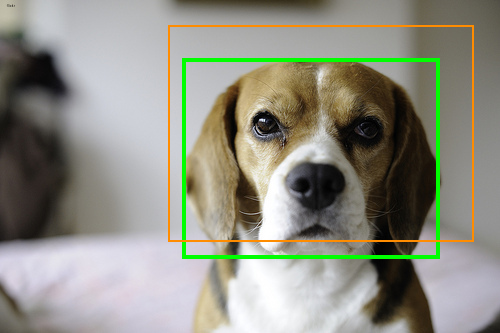

In [ ]:
# 1-3 실습 코드
# 도움말 · 초록색이 정답이고 주황색이 예측입니다. 좌표 반올림은 마지막 출력에서만 합니다.
# 여기에 풀이를 작성하세요.
key = "beagle_111"
# predictions(공통 준비 셀) = 평가 48장의 모델 예측표
#   image = 사진 ID, label = 예측 종, score = 그 종의 확률(신뢰도), box = 원본 픽셀 기준 머리 박스 XYXY
candidate = predictions.set_index("image").loc[key]  # image 열을 인덱스로 바꾼 뒤 .loc[key]로 이 사진의 예측 행 하나를 꺼냄
a = gt.loc[key,coords].to_numpy(float)  # a = 정답 머리 박스 [xmin, ymin, xmax, ymax] (gt = 평가 48장의 정답 표)
b = np.asarray(candidate.box)  # b = 예측 박스. 튜플을 numpy 배열로 바꿔야 아래에서 한꺼번에 계산 가능

# ── 교집합 구하기 ──
# a[:2] = 앞 두 값(왼쪽 x, 위 y), a[2:] = 뒤 두 값(오른쪽 x, 아래 y)
# np.maximum / np.minimum = 두 배열에서 같은 자리끼리 큰 값 / 작은 값을 고름
lo = np.maximum(a[:2], b[:2])  # 겹친 영역의 왼쪽·위 = 두 박스 중 더 안쪽(큰 값)
hi = np.minimum(a[2:], b[2:])  # 겹친 영역의 오른쪽·아래 = 두 박스 중 더 안쪽(작은 값)
sides = np.maximum(0,hi-lo)  # 겹친 너비·높이 (안 겹치면 음수 대신 0)
intersection = sides.prod()  # 교집합 넓이 = 너비 × 높이 (prod = 원소를 모두 곱함)

# ── 각 박스 넓이와 합집합 ──
area_a = np.prod(a[2:]-a[:2])  # 정답 넓이 = (오른쪽−왼쪽) × (아래−위) = 257 × 200
area_b = np.prod(b[2:]-b[:2])  # 예측 넓이
union = area_a + area_b - intersection  # 합집합 = 두 넓이의 합 − 두 번 더해진 교집합

print("예측 박스",np.round(b,2),"겹친 구간",lo.round(2),hi.round(2))  # → 예측 [169, 25.48, 473.82, 241.08], 겹친 구간 [182, 58] ~ [439, 241.08]
print("정답/예측/교집합/합집합 면적",np.round([area_a,area_b,intersection,union],2))  # → [51400, 65721.01, 47052.33, 70068.68]
print("IoU",round(intersection/union,6))  # IoU = 교집합 / 합집합 → 0.671517
# assert 조건: 조건이 False면 에러를 내고 멈춤 → 직접 계산한 IoU가
#   제공 함수 box_parts의 세 번째 반환값(IoU, 인덱스 [2])과 같은지 검산 (np.isclose = 실수 오차 허용 비교)
assert np.isclose(intersection/union,box_parts(a,b)[2])
show_box(key,b)  # 원본 위에 정답(초록)과 예측(주황) 박스를 겹쳐 그림

#### 1-3 정답 및 해설

**답**　비글의 정답 박스는 (182, 58, 439, 258)이고, 모델 예측은 약 (169.00, 25.48, 473.82, 241.08)입니다. 그림에서 주황 박스가 정답보다 왼쪽·오른쪽·위로 더 넓고, 아래에서는 정답의 끝까지 닿지 않는지 확인하세요.

공통 구간이 되려면 두 박스 모두의 안쪽에 있어야 합니다. 왼쪽은 max(182, 169.00) = 182, 오른쪽은 min(439, 473.82) = 439입니다. 위는 58, 아래는 약 241.08이어서 겹친 너비는 257, 높이는 약 183.08입니다. 둘을 곱한 실제 교집합은 **47,052.33 픽셀²**입니다. 서로 겹치지 않을 때 음수 길이를 0으로 바꾸는 줄이 `np.maximum(0, hi-lo)`입니다.

정답 면적 257×200 = 51,400과 예측 면적을 더하면 겹친 부분이 두 번 들어갑니다. 그래서 교집합 한 번을 빼 합집합 **70,068.67 픽셀²**를 얻습니다. IoU는 47,052.33 ÷ 70,068.67 ≈ **0.671517**입니다. 좌표는 연속값이므로 너비와 높이에 1을 더하지 않습니다. 화면에 표시한 반올림 좌표 대신 실제 배열로 검산해야 마지막 자릿수까지 맞습니다.

### 1-4. 같은 후보의 판정이 기준에 따라 달라지는 이유

beagle_111과 Abyssinian_1에서 예측 종, 종 점수, 박스 IoU, IoU 0.50·0.75의 판정을 출력하세요. 두 사진 중 종을 맞혔지만 0.50에서도 검출에 실패한 사진을 찾고 “점수”와 “위치 정확도”를 구분하세요.

In [ ]:
# 1-4 실습 코드
# 도움말 · 판정에는 종 일치와 IoU 기준 충족이 모두 필요합니다.
# 여기에 풀이를 작성하세요.
by_id = predictions.set_index("image")  # 사진 ID로 예측 행을 바로 찾도록 image 열을 인덱스로 바꿈
for key in ["beagle_111","Abyssinian_1"]:  # 두 사진을 차례로 검사
    row = by_id.loc[key]  # 이 사진의 예측 (label = 예측 종, score, box)
    actual = gt.loc[key]  # 이 사진의 정답 (object_name = 실제 종, 머리 박스 좌표)
    _,_,iou = box_parts(actual[coords].to_numpy(float),row.box)  # box_parts는 (교집합, 합집합, IoU) 세 값을 돌려줌
    # _ = 쓰지 않는 값을 버리는 자리, 세 번째 IoU만 받음
    ok = row.label == actual.object_name  # 예측 종 = 실제 종이면 True
    # [... for t in [0.50,0.75]] → IoU 기준 두 개 각각에 대해 "종 일치 그리고 IoU ≥ 기준"인지 True/False 목록
    #   bool(...)은 출력을 True/False로 깔끔하게 보이게 함
    # 종 점수(score)는 cat·dog 중 고른 종의 Softmax 확률일 뿐, 박스 위치가 맞는지와는 별개임
    # → beagle_111: 종 맞음, IoU 0.6715 → [True, False] (0.50 통과, 0.75 실패)
    # → Abyssinian_1: 종 맞음, 종 점수 0.5422로 더 높지만 IoU 0.1922 → [False, False]
    print(key, "실제/예측",actual.object_name,row.label, "종 점수",round(row.score,4),
          "IoU",round(iou,4), "통과(0.50, 0.75)", [bool(ok and iou >= t) for t in [0.50,0.75]])

beagle_111 실제/예측 dog dog 종 점수 0.5201 IoU 0.6715 통과(0.50, 0.75) [True, False]
Abyssinian_1 실제/예측 cat cat 종 점수 0.5422 IoU 0.1922 통과(0.50, 0.75) [False, False]


#### 1-4 정답 및 해설

**답**　beagle_111은 dog를 맞혔고 IoU 0.6715라 0.50 기준은 통과하지만 0.75 기준은 통과하지 못합니다. Abyssinian_1은 cat을 맞혔으나 IoU 약 0.1922여서 두 기준 모두 실패합니다.

비글의 종 점수는 약 0.5201, 고양이의 종 점수는 약 0.5422입니다. 두 값은 모델이 사진을 cat·dog 중 하나로 고를 때 선택한 쪽의 Softmax 값입니다. 반면 박스 IoU를 얻기 위해서는 사람이 표시한 정답 좌표가 있어야 합니다. 이 고양이는 종 점수가 비글보다 높으면서 박스 IoU는 더 낮습니다. “어느 종 같아 보이는가”와 “머리를 얼마나 정확히 둘렀는가”가 다른 질문이라는 것을 두 파일만으로 확인할 수 있습니다.

검출에서는 종이 맞아도 위치가 부족하면 그 후보는 FP이며, 이 사진에 다른 올바른 후보가 없다면 해당 정답은 FN으로 남습니다. 사진 하나에서 FP와 FN이 함께 생길 수 있는 이유입니다.

## 필수 2 · 한 정답을 한 번만 세고 실제 예측으로 AP 계산하기

### 2-1. 두 사진과 네 후보에서 중복·오분류 구별하기

교안 연습 후보 A~D를 점수 순으로 검토하세요. 점수 기준 0.50과 0.80에서 각각 TP·FP·FN을 세고, B의 IoU가 충분한데도 TP가 되지 않는 이유를 쓰세요.

In [ ]:
# 2-1 실습 코드
# 도움말 · 연습 후보는 같은 이미지에 둘 이상 있을 수 있습니다. 각 기준에서 연결 기록을 비우고 시작하세요.
# 여기에 풀이를 작성하세요.
# toy = 공통 준비 셀의 연습용 가짜 후보 A~D (A·B는 Abyssinian_1의 고양이 후보, C·D는 beagle_110의 후보)
# toy_gt = 그 두 사진의 정답 (사진당 머리 1개: Abyssinian_1 = cat, beagle_110 = dog)
toy_gt = pool.loc[["Abyssinian_1","beagle_110"]]
for cutoff in (0.50,0.80):  # 점수 기준 두 개를 차례로 적용 (IoU 기준은 0.50 고정)
    # match_detections(정답, 후보, min_iou=0.50, min_score=cutoff)
    #   1) 점수(score) ≥ cutoff인 후보만 남겨 점수 높은 순으로 하나씩 판정
    #   2) 종이 다르면 "클래스 오류", IoU < 0.50이면 "위치 오류"
    #   3) 그 정답이 이미 앞 후보와 연결됐으면 "중복"(FP), 아니면 TP로 연결
    #   함수 안에서 연결 기록(used)을 매번 새로 비우므로 기준마다 처음부터 판정함
    audit = match_detections(toy_gt,toy,0.50,cutoff)
    # 판정표에는 후보 이름(id)이 없어서 score 값을 열쇠로 toy 표의 id 열을 붙임
    #   merge(on="score") = 두 표에서 score가 같은 행끼리 옆으로 이어 붙임
    #   validate="one_to_one" = 각 score가 양쪽 표에 한 번씩만 있는 일대일 관계인지 확인 (아니면 에러)
    audit = audit.merge(toy[["id","score"]],on="score",validate="one_to_one")
    display(audit[["id","label","score","iou","reason"]].round(4))  # 대괄호 두 겹 = 보고 싶은 열만 골라 표로 보여 줌

    tp = int(audit.tp.sum())  # tp 열(TP면 1, 아니면 0)을 모두 더하면 TP 개수
    fp,fn = len(audit)-tp, len(toy_gt)-tp  # FP = 남은 후보 수 − TP, FN = 정답 수(2) − TP
    print("점수 기준",cutoff,"TP/FP/FN",tp,fp,fn,"P/R",tp/(tp+fp),tp/(tp+fn))  # 끝의 두 값 = Precision = TP/(TP+FP), Recall = TP/(TP+FN)
    # → 0.50: A·D가 TP, B는 중복(같은 정답을 A가 먼저 가져감), C는 클래스 오류 → TP 2, FP 2, FN 0
    # → 0.80: A만 남음 → TP 1, FP 0, FN 1

,id,label,score,iou,reason
0,A,cat,0.95,0.7222,TP
1,B,cat,0.65,0.8416,중복
2,C,cat,0.60,1.0000,클래스 오류
3,D,dog,0.55,0.8611,TP


점수 기준 0.5 TP/FP/FN 2 2 0 P/R 0.5 1.0


,id,label,score,iou,reason
0,A,cat,0.95,0.7222,TP


점수 기준 0.8 TP/FP/FN 1 0 1 P/R 1.0 0.5


#### 2-1 정답 및 해설

**답**　점수 0.50에서는 A와 D가 TP, B와 C가 FP입니다. 정답 2개를 모두 찾아 FN은 0입니다. 점수 0.80에서는 A만 남아 TP 1, FP 0, FN 1입니다.

| 후보 | 0.50에서 판정 | 판단 근거 |
|---|---|---|
| A · cat · 0.95 | TP | 고양이 머리의 예측을 가장 먼저 판정합니다. IoU는 (78×87)/(108×87) ≈ 0.7222로 기준을 넘습니다. |
| B · cat · 0.65 | FP · 중복 | IoU가 약 0.8416이라 위치는 더 정확하지만 같은 정답을 A가 이미 가져갔습니다. |
| C · cat · 0.60 | FP · 클래스 오류 | 비글 머리의 정답 좌표와 정확히 겹쳐도 실제 종 dog와 예측 cat이 다릅니다. |
| D · dog · 0.55 | TP | 비글의 실제 종과 위치 조건을 만족합니다. C는 정답을 차지하지 않았으므로 D와 연결할 수 있습니다. |

`used`에는 앞선 TP가 연결한 사진 ID가 들어갑니다. 여기서 사진 ID를 정답 키로 사용할 수 있는 이유는 평가 집합에 이미지당 정답 머리가 하나뿐이기 때문입니다. 여러 개체가 있는 사진이라면 개별 주석 ID를 써야 합니다. 0.50에서 Precision = 2/4, Recall = 2/2입니다. 0.80에서 각각 1/1, 1/2가 됩니다. 올바른 D까지 빠지므로 Precision이 오르면서 Recall이 떨어집니다. 이 표는 판정 규칙을 확인하는 연습용입니다.

### 2-2. 같은 48장에서 점수 기준 세 개 비교하기

실제 모델 결과에 점수 기준 0.50, 0.55, 0.80을 적용하세요. 박스 IoU 기준은 0.50으로 고정하고 검출 수·TP·FP·FN·Precision·Recall을 구하세요. 남은 검출이 0개일 때의 분모도 설명하세요.

In [ ]:
# 2-2 실습 코드
# 도움말 · 일치한 정답 수가 TP입니다. FP의 분모와 FN의 기준 집합을 먼저 적어보세요.
# 여기에 풀이를 작성하세요.
rows = []  # 기준별 결과를 한 줄(리스트)씩 모을 빈 리스트
for cutoff in [0.50,0.55,0.80]:  # 점수 기준 3개 (IoU 기준은 0.50 고정)
    checked = match_detections(gt,predictions,0.50,cutoff)  # 점수 ≥ cutoff인 예측만 판정한 표 (행 수 = 남은 검출 수)
    tp = int(checked.tp.sum())  # tp 열(0/1)의 합 = TP 개수
    fp,fn = len(checked)-tp,len(gt)-tp  # FP = 남은 검출 − TP, FN = 실제 정답 48개 − TP
    precision = tp/len(checked) if len(checked) else np.nan  # A if 조건 else B: 남은 검출이 있으면 TP/검출 수,
    # 0개면 0/0이 되므로 NaN(정의되지 않음)으로 둠
    rows.append([cutoff,len(checked),tp,fp,fn,precision,tp/len(gt)])  # 마지막 값 tp/len(gt) = Recall = TP / 실제 정답 수
display(pd.DataFrame(rows,columns=["score_min","검출","TP","FP","FN","precision","recall"]).round(4))  # 리스트 목록 → 표로 바꿔 소수 넷째 자리까지 표시
# → 0.50: 검출 48·TP 26·FP 22·FN 22 / 0.55: 6·6·0·42 / 0.80: 0·0·0·48 (precision NaN)
print(match_detections(gt,predictions,0.50,0.50).reason.value_counts())  # 기준 0.50의 판정 이유(reason)별 개수를 셈 (value_counts)
# → TP 26, 위치 오류 15, 클래스 오류 7

,score_min,검출,TP,FP,FN,precision,recall
0,0.50,48,26,22,22,0.5417,0.5417
1,0.55,6,6,0,42,1.0000,0.1250
2,0.80,0,0,0,48,NaN,0.0000


reason
TP        26
위치 오류     15
클래스 오류     7
Name: count, dtype: int64


#### 2-2 정답 및 해설

**답**　점수 0.50에서는 48개 예측 중 26개가 TP입니다. 남은 22개는 위치 오류 15개, 클래스 오류 7개입니다. 이 모델은 각 사진에 머리 후보를 하나만 내므로 이 표에는 중복 후보가 없습니다.

| 점수 기준 | 남은 검출 | TP · FP · FN | Precision | Recall |
|---:|---:|---|---:|---:|
| 0.50 | 48 | 26 · 22 · 22 | 26/48 = 54.17% | 26/48 = 54.17% |
| 0.55 | 6 | 6 · 0 · 42 | 6/6 = 100% | 6/48 = 12.50% |
| 0.80 | 0 | 0 · 0 · 48 | 정의되지 않음 | 0/48 = 0% |

`checked`에는 점수 문턱을 통과해 실제 평가한 후보만 남습니다. FP는 이 표의 행 수에서 TP를 뺍니다. FN은 실제 정답 48개에서 TP를 뺍니다. 첫 줄에서 Precision과 Recall이 같은 이유는 그때 후보 수도 48, 실제 정답 수도 48이기 때문입니다. 정의가 같아서가 아닙니다.

0.80에서는 분자가 0인 것과 분모까지 0인 것을 구분합니다. 검출이 없으므로 Precision은 0/0이며 코드에서 NaN으로 표시합니다. 실제 정답은 여전히 48개라 Recall은 0입니다. 놓치는 머리를 줄이는 것이 목표라면 이 표본에서 0.50이 0.55보다 적합합니다. 다른 데이터에 적용할 운영 기준을 정하려면 별도 검증 집합이 필요합니다.

### 2-3. 실제 점수 순위로 클래스별 AP와 mAP 계산하기

고양이의 상위 5개 예측에서 누적 TP·Precision·Recall을 읽으세요. 두 종에 대해 IoU 0.50부터 0.95까지 0.05 간격으로 AP를 구하고 mAP@0.50, mAP@0.50:0.95를 계산하세요.

,score,TP_cum,precision,recall
0,0.5642,1,1.00,0.0417
1,0.5612,2,1.00,0.0833
2,0.5593,3,1.00,0.1250
3,0.5466,3,0.75,0.1250
4,0.5458,3,0.60,0.1250


,cat,dog,mAP
IoU,,,
0.50,0.320431,0.520770,0.420601
0.55,0.257426,0.409342,0.333384
0.60,0.169505,0.332787,0.251146
0.65,0.117301,0.123539,0.120420
0.70,0.076379,0.035435,0.055907
0.75,0.076379,0.007072,0.041726
0.80,0.016502,0.007072,0.011787
0.85,0.000000,0.000000,0.000000
0.90,0.000000,0.000000,0.000000


mAP@0.50 0.420601
mAP@0.50:0.95 0.123497


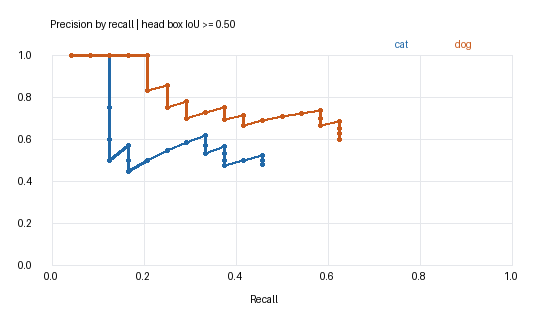

In [ ]:
# 2-3 실습 코드
# 도움말 · ap_curve는 점수 제한 없이 해당 클래스 예측을 모두 사용합니다. 한 행은 IoU 한 기준이고 한 열은 한 종입니다.
# 여기에 풀이를 작성하세요.
# ap_curve(정답, 예측, 종 이름, IoU 기준) → (AP 값, 순위별 누적표)
#   그 종으로 예측한 후보만 점수 높은 순으로 줄 세우고, 위에서부터 하나씩 포함할 때의
#   TP_cum(누적 TP, cumsum = 누적 합), precision = 누적 TP / 지금까지 후보 수, recall = 누적 TP / 그 종 정답 수
#   AP = 목표 Recall 0, 0.01, …, 1(101개)마다 그 Recall 이상에서의 최고 Precision을 구해 평균한 값
cat_ap, prefix = ap_curve(gt,predictions,"cat",0.50)
display(prefix.head(5).round(4))  # 점수 상위 5개 행만 표시
# → 1~3번째는 TP라 precision 1.0, 4·5번째는 FP라 recall은 그대로이고 precision이 0.75, 0.60으로 내려감

# ── IoU 기준 10개 × 종 2개의 AP 표 ──
ap_rows = []
for step in range(50,100,5):  # 50, 55, …, 95 (끝값 100은 포함 안 됨)
    cutoff = step/100  # → IoU 기준 0.50, 0.55, …, 0.95
    # [cutoff] + [cat의 AP, dog의 AP] → 한 행 = [IoU 기준, cat AP, dog AP]
    #   ap_curve(...)[0] = 돌려준 두 값 중 첫 번째(AP 숫자)만 사용
    ap_rows.append([cutoff] + [ap_curve(gt,predictions,name,cutoff)[0] for name in species])
ap_table = pd.DataFrame(ap_rows, columns=["IoU",*species]).set_index("IoU")  # *species = 리스트를 풀어 넣음 → 열 이름 ["IoU","cat","dog"]
# set_index("IoU") = IoU 열을 행 이름(인덱스)으로 사용
ap_table["mAP"] = ap_table[species].mean(axis=1)  # axis=1 = 같은 행(같은 IoU 기준)에서 cat·dog 두 열을 평균 → 그 기준의 mAP
display(ap_table.round(6))  # → IoU 0.50: cat 0.320431, dog 0.520770, mAP 0.420601 / 0.85 이상은 모두 0

print("mAP@0.50",round(ap_table.loc[0.50,"mAP"],6))  # IoU 0.50 행의 mAP → 0.420601
print("mAP@0.50:0.95",round(ap_table.mAP.mean(),6))  # 10개 IoU 기준의 mAP를 다시 평균 → 0.123497 (엄격한 기준까지 포함해 더 낮음)

# ── Precision-Recall 그래프 그리기 (PIL로 직접 그림) ──
# 흰 바탕 560×320 그림과 그 위에 그릴 펜(ImageDraw) 준비
chart = Image.new("RGB",(560,320),"white")
pen = ImageDraw.Draw(chart)
# 격자와 눈금: 0.0, 0.2, …, 1.0의 6개
#   그래프 영역은 가로 x = 52~512(460픽셀), 세로 y = 55~265(210픽셀)
#   그림 좌표는 y가 아래로 갈수록 커지므로 265 − r×210으로 위아래를 뒤집음
for tick in range(6):
    r = tick/5  # 눈금 값 0.0 ~ 1.0
    x_pos, y_pos = 52+int(r*460), 265-int(r*210)  # 눈금 값을 그림 픽셀 위치로 변환
    pen.line((x_pos,55,x_pos,265), fill="#e5e7eb")  # 세로 격자선
    pen.line((52,y_pos,512,y_pos), fill="#e5e7eb")  # 가로 격자선
    pen.text((x_pos-8,270),f"{r:.1f}",fill="black")  # 가로축(Recall) 눈금 글자
    pen.text((18,y_pos-6),f"{r:.1f}",fill="black")  # 세로축(Precision) 눈금 글자

pen.text((50,18),"Precision by recall | head box IoU >= 0.50",fill="black")  # 그래프 제목
pen.text((250,293),"Recall",fill="black")  # 가로축 이름

# 종마다 IoU 0.50의 순위별 (recall, precision) 점을 그림 좌표로 바꿔 선과 점으로 그림
for name,color in [("cat","#2269a8"),("dog","#c95a1b")]:
    _, points = ap_curve(gt,predictions,name,0.50)  # AP 값은 버리고(_) 순위별 누적표만 사용
    xy = [(52+float(r)*460,265-float(pr)*210) for r,pr in zip(points.recall,points.precision)]  # zip으로 recall·precision을 한 쌍씩 묶어 픽셀 좌표 (x, y) 목록으로 변환
    if len(xy)>1:  # 점이 2개 이상일 때만 선으로 연결
        pen.line(xy,fill=color,width=3)
    for x_pos,y_pos in xy:  # 각 순위 시점마다
        pen.ellipse((x_pos-2,y_pos-2,x_pos+2,y_pos+2),fill=color)  # 반지름 2픽셀의 점을 찍음
    pen.text((395 if name=="cat" else 455,38),name,fill=color)  # 범례: cat은 x=395, dog는 x=455 위치에 종 이름을 그 색으로 표시
display(chart)  # 완성된 그래프 표시

#### 2-3 정답 및 해설

**답**　IoU 0.50에서 고양이 AP는 **0.320431**, 개 AP는 **0.520770**, 두 클래스 mAP는 약 **0.420601**입니다. 열 개 IoU 기준과 두 종을 함께 평균하면 약 **0.123497**입니다.

1. **순위 한 줄부터 읽기**　고양이 예측을 점수 내림차순으로 정렬합니다. 첫 세 후보가 모두 TP라 세 번째 행까지의 Precision은 3/3 = 1, Recall은 3/24 = 0.125입니다. 네 번째 후보는 TP를 추가하지 못해 Precision은 3/4 = 0.75, Recall은 그대로 0.125입니다. 같은 방식으로 다섯 번째 행은 3/5 = 0.60입니다.
2. **AP로 묶기**　사용한 방식은 101점 보간 AP입니다. 목표 Recall을 0, 0.01, …, 1까지 바꿉니다. 각 목표 이상에 도달한 순위들 중 가장 높은 Precision을 기록하고, 목표에 도달하지 못하면 0으로 둡니다. 그 101개 값을 평균합니다. 그래서 상위 몇 건의 Precision만 평균하는 계산과 다릅니다. 첫 다섯 줄은 계산의 출발을 보여주며 실제 AP에는 마지막 후보까지 사용합니다.
3. **mAP로 묶기**　첫 행에서 (0.320431 + 0.520770)/2 ≈ 0.420601입니다. 표의 끝 0.85, 0.90, 0.95에서는 이 표본의 AP가 0입니다. 위치가 더 엄격한 기준까지 포함하므로 열 개 행 평균이 0.50의 한 행 값보다 낮습니다. 교안의 균열 AP 0.80, 흠집 AP 0.60을 평균해 0.70을 얻는 것과 같은 평균 원리를 실제 두 종에 적용한 것입니다.

이 수치는 단일 머리·두 종·48장의 수업용 평가 결과입니다. 101점 보간과 IoU 간격을 사용했지만 공식 COCO의 전체 클래스, 면적 구간, 군중 주석, 최대 검출 수 등의 평가 설정을 그대로 수행한 결과는 아닙니다.

**그래프 읽기**　가로축은 Recall, 세로축은 Precision입니다. 점은 점수 순서로 후보 한 개를 더 포함한 시점입니다. FP가 들어오면 Recall은 같은 위치에 머물며 Precision이 내려갑니다. 그림은 실제 순위의 점들을 연결했고, AP 숫자는 이 점들에서 101개 목표 Recall의 보간값을 구해 계산했습니다.

### 2-4. 한 줄의 Precision이 높은데 mAP는 낮을 수 있을까?

2-2와 2-3의 값을 인용해 점수 기준과 IoU 기준을 각각 올리면 무엇이 바뀌는지 서술하세요. Precision 100%와 mAP@0.50 약 0.42가 같은 모델에서 함께 나오는 이유를 쓰세요.

#### 2-4 정답 및 해설

**예시 답안**　점수 기준 0.55에서는 모델이 남긴 6개가 모두 정답이므로 Precision은 100%입니다. 실제 머리 48개 중 남은 42개는 맞히지 못해 Recall은 12.5%입니다. AP는 이 여섯 후보의 정오만 묻지 않습니다. 점수가 낮은 후보를 차례로 포함했을 때 정답을 얼마나 더 회수하고 오답이 얼마나 따라오는지 클래스별 순위 전체를 반영합니다.

점수 기준은 “모델 출력을 몇 개 남기는가?”를 바꿉니다. IoU 기준은 “남겨둔 후보가 정답 위치에 얼마나 가까워야 TP인가?”를 바꿉니다. 예를 들어 비글의 박스는 그대로 두어도 IoU 0.50에서는 TP이고 0.75에서는 위치 오류입니다. 높은 점수의 후보만 통과시켜 한 줄의 Precision을 높이는 방법으로 엄격한 박스 위치 기준까지 자동으로 충족할 수는 없습니다.

## 과제 · 실제 몸 마스크에서 누락·과다 예측을 찾아 결과 해석하기

### 3-1. 4×4 마스크를 움직여 지표의 분모 검산하기

교안 4×4 예시에서 공통·과다·누락 픽셀의 수와 좌표(행, 열)를 출력하고 IoU·Dice를 구하세요. 예측을 왼쪽으로 한 칸 옮겨 오른쪽 끝을 0으로 채운 뒤 같은 지표를 다시 계산하세요.

In [ ]:
# 3-1 실습 코드
# 도움말 · np.roll을 그대로 쓰면 오른쪽 끝으로 픽셀이 되돌아올 수 있습니다. 빈 배열에 필요한 열만 복사하세요.
# 여기에 풀이를 작성하세요.

**나의 답안**

- 실제 출력 또는 계산 근거
- 결과 해석

### 3-2. 비글의 몸에서 틀린 9칸은 어디인가?

beagle_111의 종·머리 점수와 구분해서 몸 마스크를 평가하세요. 픽셀 확률 기준 0.50에서 미분류 칸을 제외하고 TP·FP·FN과 IoU·Dice를 직접 계산하세요. 원본·정답·예측·오차 그림을 나란히 표시하세요.

In [ ]:
# 3-2 실습 코드
# 도움말 · 40×40에서 계산하고 시각화할 때만 확대하세요. 오류 그림에서 미분류 픽셀의 색을 따로 두세요.
# 여기에 풀이를 작성하세요.

**나의 답안**

- 실제 출력 또는 계산 근거
- 결과 해석

### 3-3. 픽셀 기준이 높아지면 평균 마스크가 좋아지는가?

동일한 몸 확률맵을 0.50과 0.70에서 이진화하세요. beagle_111과 Abyssinian_1의 과다·누락·두 지표, 전체 48장의 사진별 평균 IoU와 Dice를 비교하세요.

In [ ]:
# 3-3 실습 코드
# 도움말 · 모델을 다시 학습하지 않습니다. 같은 body_prob에서 비교 연산자 오른쪽의 값만 바꿉니다.
# 여기에 풀이를 작성하세요.

**나의 답안**

- 실제 출력 또는 계산 근거
- 결과 해석

### 3-4. 찾은 머리의 사진만 남겨도 되는가?

머리 기준(점수 0.50, 박스 IoU 0.50)에서 통과한 사진·실패한 사진·전체의 몸 마스크 평균 IoU와 장수를 비교하세요. 제품이 머리를 찾은 뒤 몸 결과를 보여준다면 어떤 수치를 함께 보고해야 하나요?

In [ ]:
# 3-4 실습 코드
# 도움말 · 사진 ID로 검출 판정과 마스크 지표를 연결하세요. 평가 대상 48장이 모두 결과에 남았는지 확인합니다.
# 여기에 풀이를 작성하세요.

**나의 답안**

- 실제 출력 또는 계산 근거
- 결과 해석

## 실습 마무리

### 실습 마무리 · 예시 답안

**1. 한 사진의 결과**　Abyssinian_1을 모델은 고양이로 맞혔지만 머리 좌표는 IoU 0.1922로 정답 박스와 충분히 겹치지 않았습니다. 같은 사진의 몸 마스크 IoU는 픽셀 기준 0.50에서 0.7935였습니다. 클래스 이름, 머리 위치, 몸 영역을 구분하지 않으면 “이 사진을 맞혔다”는 말만으로는 무엇을 평가했는지 알기 어렵습니다.

**2. 세 문턱의 차이**　종 점수 기준을 0.50에서 0.55로 올려 남은 후보가 48개에서 6개로 줄었습니다. 머리 IoU 기준을 올리는 것은 이미 얻은 후보와 정답의 공간적 일치에 더 엄격한 점수를 요구하는 일입니다. 몸 픽셀 기준을 올리는 것은 40×40의 각 칸이 전경이 되기 위한 조건을 바꾸는 일입니다. beagle_111에서는 그 결과 누락 칸이 9개에서 33개로 늘었습니다.

**3. 판단 근거**　소표본 두 종의 머리 mAP@0.50은 0.420601, 더 엄격한 기준까지 평균한 값은 0.123497이었습니다. 몸 마스크의 48장 평균 IoU는 픽셀 기준 0.50에서 0.839045였습니다. 머리를 찾은 26장만 보면 몸 IoU가 0.852487로 달라지므로, 어떤 사진을 평균에 넣었는지도 수치와 함께 명시합니다. 이 실험의 범위는 사진당 주석 머리 한 개, 두 종, 40×40 몸 마스크입니다.